In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBRanker
from sklearn.metrics import mean_absolute_error, make_scorer
from scipy.stats import spearmanr

In [ ]:
data = pd.read_csv('/content/20_26_PLTable_Features_simplified.csv')
# data.info()

In [ ]:
# Label transformation for ranking
# XGBRanker expects larger label => "more relevant"
# We want Pos=1 to be the highest label
data['RankLabel'] = data.groupby('Season')['Pos'].transform(lambda x: x.max() + 1 - x)
# e.g. max pos in a season is 20, Pos=1 -> label=20, Pos=20 -> label=1
#                                        Pos=2 -> label=19, Pos=19 -> label=2

In [ ]:
# Features
features = ['Points', 'Won', 'Lost', 'Draw', 'GD', 'GF', 'GA', 'Num of Seasons', '3yr History',
            'AvgPoints 3yr', 'AvgGD 3yr', 'AvgGF 3yr', 'AvgGA 3yr', 'Promoted' ]

# Split into train / test / validation sets by season
train_data = data[data['Season'] < 2425].copy()
val_data = data[data['Season'] == 2425].copy()
test_data = data[data['Season'] == 2526].copy()

x_train = train_data[features]
y_train = train_data['RankLabel']

x_val = val_data[features]
y_val = val_data['RankLabel']

x_test = test_data[features]
y_test = test_data['Pos']   # keep original Pos

# Identify seasons
train_seasons = sorted(train_data['Season'].unique())

# Create groups for each season
train_groups = train_data.groupby('Season').size().to_list()
val_groups = val_data.groupby('Season').size().to_list()
test_groups  = test_data.groupby('Season').size().to_list()

In [ ]:
from itertools import product

# param_grid = {
#     'learning_rate': [0.025, 0.05, 0.075],
#     'n_estimators': [200, 400, 600],
#     'max_depth': [3, 5, 7],
#     'min_child_weight': [1, 3, 5],
#     'subsample': [0.55, 0.65, 0.65],
#     'colsample_bytree': [0.65, 0.75, 0.85],
#     'gamma': [0.05, 0.1, 0.15],
#     'reg_alpha': [0.01, 0.05, 0.1],
#     'reg_lambda': [1.0, 2.5, 5.0]
# }

param_grid = {
    'learning_rate': [0.06, 0.07],
    'n_estimators': [16, 18, 20],
    'max_depth': [2, 3, 4],
    'min_child_weight': [1, 2],
    'subsample': [0.7, 0.75, 0.8],
    'colsample_bytree': [0.55, 0.6, 0.65],
    'gamma': [0.2, 0.25, 0.3],
    'reg_alpha': [0.03, 0.04],
    'reg_lambda': [9.0, 10.0]
}

best_params = None
best_spearman = -np.inf
count = 0

for lr, ne, md, mcw, ss, cs, gm, ra, rl in product(
    param_grid['learning_rate'],
    param_grid['n_estimators'],
    param_grid['max_depth'],
    param_grid['min_child_weight'],
    param_grid['subsample'],
    param_grid['colsample_bytree'],
    param_grid['gamma'],
    param_grid['reg_alpha'],
    param_grid['reg_lambda']
):
    count += 1

    model = XGBRanker(
        objective='rank:pairwise',
        learning_rate=lr,
        n_estimators=ne,
        max_depth=md,
        min_child_weight=mcw,
        subsample=ss,
        colsample_bytree=cs,
        gamma=gm,
        reg_alpha=ra,
        reg_lambda=rl,
        random_state=0,
        verbosity=0
    )

    # Fit INSIDE the loop
    model.fit(x_train, y_train, group=train_groups)

    # Evaluate and predict on VALIDATION, not TEST
    val_scores = model.predict(x_val)

    tmp = val_data.copy()
    tmp["Pred_Score"] = val_scores
    tmp["Pred_Pos"] = tmp.groupby("Season")["Pred_Score"]\
                         .rank(ascending=False).astype(int)

    spearman = spearmanr(tmp["RankLabel"], tmp["Pred_Pos"]).correlation

    if spearman > best_spearman:
        best_spearman = spearman
        best_params = {
            'learning_rate': lr,
            'n_estimators': ne,
            'max_depth': md,
            'min_child_weight': mcw,
            'subsample': ss,
            'colsample_bytree': cs,
            'gamma': gm,
            'reg_alpha': ra,
            'reg_lambda': rl
        }

print("Best Spearman:", best_spearman)
print("Best params:")
print(best_params)

Best Spearman: -0.9642723510050297
Best params:
{'learning_rate': 0.07, 'n_estimators': 16, 'max_depth': 3, 'min_child_weight': 1, 'subsample': 0.75, 'colsample_bytree': 0.6, 'gamma': 0.25, 'reg_alpha': 0.03, 'reg_lambda': 10.0}


In [ ]:
# Tuned params

train_sizes = []
train_scores = []
valid_scores = []

for i in range(2, len(train_seasons) + 1):
    # Progressively include more seasons
    used_seasons = train_seasons[:i]
    subset = train_data[train_data['Season'].isin(used_seasons)]

    X_sub = subset[features]
    y_sub = subset['RankLabel']
    groups_sub = subset.groupby('Season').size().to_list()

    ranker = XGBRanker(
        objective='rank:pairwise',
        learning_rate=0.07,
        n_estimators=16,
        max_depth=3,
        min_child_weight=1,
        subsample=0.75,
        colsample_bytree=0.6,
        gamma=0.25,
        reg_alpha=0.03,
        reg_lambda=10.0,
        random_state=0,
        verbosity=0
    )

    ranker.fit(
        X_sub, y_sub,
        group=groups_sub
    )

    # Train performance
    train_pred = ranker.predict(X_sub)
    train_tmp = subset.copy()
    train_tmp['Pred_Score'] = train_pred
    train_tmp['Pred_Pos'] = train_tmp.groupby('Season')['Pred_Score'] \
                                       .rank(ascending=False).astype(int)

    train_spear = spearmanr(train_tmp['Pos'], train_tmp['Pred_Pos']).correlation

    # Validation performance
    val_pred = ranker.predict(x_val)
    val_tmp = val_data.copy()
    val_tmp['Pred_Score'] = val_pred
    val_tmp['Pred_Pos'] = val_tmp.groupby('Season')['Pred_Score'] \
                                   .rank(ascending=False).astype(int)

    val_spear = spearmanr(val_tmp['Pos'], val_tmp['Pred_Pos']).correlation

    train_sizes.append(len(subset))
    train_scores.append(train_spear)
    valid_scores.append(val_spear)

# Model fit
# Pass group=train_groups to tell XGB how the rows are grouped for ranking
# ranker.fit(x_train, y_train, group=train_groups, verbose=True)
# early stopping and validation set to prevent overfitting
ranker.fit(
    x_train, y_train,
    group=train_groups,
    eval_set=[(x_val, y_val)],
    eval_group=[val_groups],
    verbose=True
)

# Predict
val_scores = ranker.predict(x_val)
pred_scores = ranker.predict(x_test)

val_data = val_data.copy()
val_data['Pred_Score'] = val_scores
val_data['Pred_Pos'] = val_data.groupby('Season')['Pred_Score'] \
                           .rank(method='first', ascending=False).astype(int)
# Higher score => better predicted finish. Convert to predicted positions:
test_data = test_data.copy()
test_data['Pred_Score'] = pred_scores
# Rank by descending predicted score to create predicted finishing position:
test_data['Pred_Pos'] = test_data.groupby('Season')['Pred_Score'] \
                             .rank(method='first', ascending=False).astype(int)

[0]	validation_0-ndcg@32:1.00000
[1]	validation_0-ndcg@32:0.99989
[2]	validation_0-ndcg@32:0.99989
[3]	validation_0-ndcg@32:0.99989
[4]	validation_0-ndcg@32:0.99989
[5]	validation_0-ndcg@32:1.00000
[6]	validation_0-ndcg@32:1.00000
[7]	validation_0-ndcg@32:0.99998
[8]	validation_0-ndcg@32:0.99435
[9]	validation_0-ndcg@32:0.99435
[10]	validation_0-ndcg@32:0.99426
[11]	validation_0-ndcg@32:0.99426
[12]	validation_0-ndcg@32:0.96241
[13]	validation_0-ndcg@32:0.96217
[14]	validation_0-ndcg@32:0.96224
[15]	validation_0-ndcg@32:0.96224


In [ ]:
# Evaluation
val_mae_pos = mean_absolute_error(val_data['Pos'], val_data['Pred_Pos'])
val_spearman_pos, _ = spearmanr(val_data['Pos'], val_data['Pred_Pos'])
val_spearman_score, _ = spearmanr(val_data['Pos'], val_data['Pred_Score'])

mae_pos = mean_absolute_error(test_data['Pos'], test_data['Pred_Pos'])
spearman_pos, _ = spearmanr(test_data['Pos'], test_data['Pred_Pos'])
spearman_score, _ = spearmanr(test_data['Pos'], test_data['Pred_Score'])

print("Val MAE (positions):", round(val_mae_pos, 3))
print("Val Spearman (positions):", round(val_spearman_pos, 3))
print("Val Spearman (pos vs score):", round(val_spearman_score, 3))

print("Test MAE (positions):", round(mae_pos, 3))
print("Test Spearman (positions):", round(spearman_pos, 3))
print("Spearman (pos vs score):", round(spearman_score, 3))

Val MAE (positions): 1.2
Val Spearman (positions): 0.965
Val Spearman (pos vs score): -0.964
Test MAE (positions): 1.7
Test Spearman (positions): 0.896
Spearman (pos vs score): -0.821


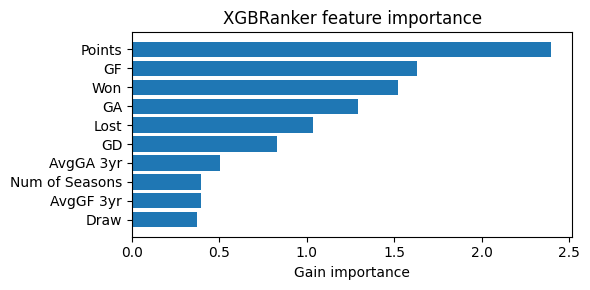

    Abb  Pos  Pred_Pos  Pred_Score
0   ARS    1         2    0.029820
1   MCI    2         1    0.036013
2   AVL    3         3    0.007087
3   LIV    4         4   -0.085301
4   CHE    5         5   -0.085301
5   MUN    6         6   -0.085301
6   SUN    7        16   -0.119497
7   EVE    8         7   -0.085301
8   BRE    9        12   -0.099899
9   CRY   10         8   -0.085301
10  FUL   11        13   -0.099899
11  TOT   12         9   -0.085301
12  NEW   13        10   -0.085301
13  BHA   14        11   -0.085301
14  BOU   15        14   -0.117584
15  LEE   16        18   -0.137181
16  NFO   17        15   -0.117584
17  WHU   18        17   -0.122583
18  BUR   19        19   -0.137181
19  WOL   20        20   -0.170306


In [ ]:
# Feature importance
importance = ranker.get_booster().get_score(importance_type='gain')
# Make a simple plot
names, gains = zip(*sorted(importance.items(), key=lambda kv: kv[1], reverse=True)) if importance else ([],[])
plt.figure(figsize=(6,3))
plt.barh(range(len(names)), list(gains)[::-1])
plt.yticks(range(len(names)), list(names)[::-1])
plt.xlabel("Gain importance")
plt.title("XGBRanker feature importance")
plt.tight_layout()
plt.show()

print(test_data[['Abb', 'Pos', 'Pred_Pos', 'Pred_Score']].sort_values('Pos'))

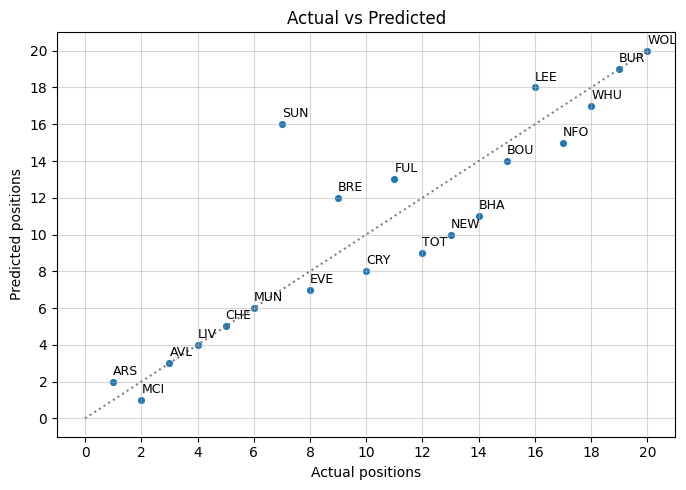

In [ ]:
import matplotlib.patches as patches
# True vs predicted
%matplotlib inline

plt.figure( figsize=(7,5) )

sns.scatterplot( x=y_test, y=test_data['Pred_Pos'], marker='.', s=150 )

for i, row in test_data.iterrows():
    plt.annotate(
        row['Abb'],
        (row['Pos'], row['Pred_Pos']),
        textcoords="offset points",
        xytext=(0,5),
        ha='left',
        fontsize=9
    )

plt.xlabel( 'Actual positions' )
plt.ylabel( 'Predicted positions' )
plt.title( 'Actual vs Predicted' )
# Ideal line
plt.plot([0, 20], [0, 20], ':', color='gray')
# Set ticks every 2 positions
plt.xticks(range(0, 21, 2))
plt.yticks(range(0, 21, 2))
plt.grid( alpha=0.5 )
plt.tight_layout()
plt.show()

In [ ]:
# From looking at the residuals (difference between actual and predicted)
# only one team is overperforming based on the model, all other teams are +
# or - 1. Meaning the model is capturing relative team strength very well and
# the learned ranking function is stable across the table
# The anomalous team is acceptable as they appear to be overperforming for a
# newly promoted team

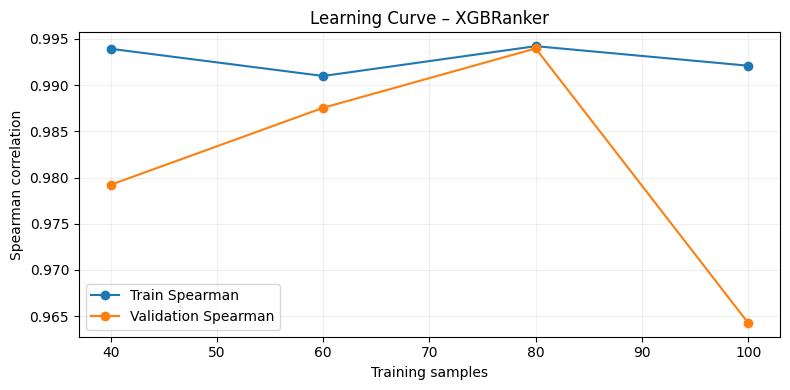

[np.float64(0.9939329494481479), np.float64(0.9909914204230978), np.float64(0.9942180766716335), np.float64(0.9921039706228123)]
[np.float64(0.9792217957108169), np.float64(0.9875509832327799), np.float64(0.9939739040519429), np.float64(0.9642723510050297)]


In [ ]:
# Learning curve plot
plt.figure(figsize=(8,4))

plt.plot(train_sizes, train_scores, marker='o', label='Train Spearman')
plt.plot(train_sizes, valid_scores, marker='o', label='Validation Spearman')
plt.xlabel("Training samples")
plt.ylabel("Spearman correlation")
plt.title("Learning Curve – XGBRanker")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print( train_scores )
print( valid_scores )

In [ ]:
# Results show that theres no underfitting as train and validation scores are low
# Maybe slight overfitting as training score is a lot higher than validation score
# Step 3 is very close so theres good generalisation
# Well-regularised, high-capacity model with slight variance

In [ ]:
# Export to tableau

export_cols = [
    'Season',
    'Abb',
    'Team Num',
    'Pos',
    'Pred_Pos',
    'Pred_Score',
    'Points',
    'GD',
    'GF',
    'GA',
    'Promoted',
    'AvgPoints 3yr',
    'AvgGD 3yr'
]

tableau_data = test_data[export_cols].copy()
tableau_data['Residual'] = tableau_data['Pred_Pos'] - tableau_data['Pos']

tableau_data.to_csv("20_26_PLTable_Predictions_Tableau.csv", index=False)
